In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('crop_yield.csv')

In [4]:
df.head(10)

,FARM_ID,CROP_TYPE,YIELD_KG,AREA_ACRES,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED,YIELD_VALUE
0,F001,Wheat,1500.0,4.0,01/01/2023,Sialkot,Rabi,Yes,30000
1,F002,Wheat,1500.0,5.0,02/01/2023,Multan,Rabi,No,30000
2,F003,Wheat,2500.0,5.0,03/01/2023,Faisalabad,Rabi,Yes,50000
3,F004,Wheat,1500.0,NaN,04/01/2023,Multan,Rabi,Yes,30000
4,F005,Rice,1500.0,4.0,05/01/2023,Faisalabad,Rabi,No,30000
5,F006,Rice,2000.0,6.0,06/01/2023,Faisalabad,Rabi,Yes,40000
6,F007,Maize,1500.0,6.0,07/01/2023,Faisalabad,Rabi,No,30000
7,F008,Wheat,1500.0,5.0,08/01/2023,Lahore,Rabi,No,30000
8,F009,Wheat,2000.0,5.0,09/01/2023,Faisalabad,Rabi,Yes,40000
9,F010,Wheat,1500.0,3.0,10/01/2023,Faisalabad,Rabi,Yes,30000


In [5]:
df.isnull().sum()

FARM_ID              0
CROP_TYPE            0
YIELD_KG           330
AREA_ACRES         144
HARVEST_DATE         0
DISTRICT           126
SEASON               0
FERTILIZER_USED    318
YIELD_VALUE          0
dtype: int64

In [6]:
df.dtypes

FARM_ID                str
CROP_TYPE              str
YIELD_KG           float64
AREA_ACRES         float64
HARVEST_DATE           str
DISTRICT               str
SEASON                 str
FERTILIZER_USED        str
YIELD_VALUE          int64
dtype: object

In [7]:
df.describe()

,YIELD_KG,AREA_ACRES,YIELD_VALUE
count,2670.000000,2856.000000,3000.000000
mean,2014.232210,4.420168,39657.780000
std,407.846962,0.979259,8405.078755
min,1500.000000,3.000000,20068.000000
25%,1500.000000,4.000000,30000.000000
50%,2000.000000,4.000000,40000.000000
75%,2500.000000,5.000000,50000.000000
max,2500.000000,6.000000,50000.000000


In [10]:
df.describe(include='str')

,FARM_ID,CROP_TYPE,HARVEST_DATE,DISTRICT,SEASON,FERTILIZER_USED
count,3000,3000,3000,2874,3000,2682
unique,3000,4,3000,4,2,2
top,F001,Wheat,01/01/2023,Faisalabad,Rabi,Yes
freq,1,1158,1,936,1528,1776


In [11]:
df = df.dropna(subset=['YIELD_KG'])

In [12]:
df.shape

(2670, 9)

In [13]:
df['AREA_ACRES'].mean()

np.float64(4.412667191188041)

In [15]:
df['AREA_ACRES'] = df['AREA_ACRES'].fillna(df['AREA_ACRES'].mean())

In [17]:
df['AREA_ACRES'].isnull().sum()

np.int64(0)

In [18]:
df['DISTRICT'] = df['DISTRICT'].fillna('Unknown')

In [19]:
df['DISTRICT'].isnull().sum()

np.int64(0)

In [20]:
df['FERTILIZER_USED'] = df['FERTILIZER_USED'].fillna('No')

In [21]:
df['FERTILIZER_USED'].isnull().sum()

np.int64(0)

In [22]:
df['YIELD_VALUE'].mean()

np.float64(40284.644194756554)

In [23]:
df['YIELD_VALUE'] = df['YIELD_VALUE'].fillna(df['YIELD_VALUE'].mean())

In [24]:
df['YIELD_VALUE'].isnull().sum()

np.int64(0)

In [25]:
df['HARVEST_DATE'] = pd.to_datetime(
    df['HARVEST_DATE'],
    errors='coerce',
    format='%d/%m/%Y'
)

In [26]:
df['HARVEST_DATE'].dtype

dtype('<M8[us]')

In [28]:
df.dtypes

FARM_ID                       str
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

In [30]:
df['FARM_ID'] = df['FARM_ID'].str.replace('F', '').astype(int)

In [31]:
df['FARM_ID'].head(10)

0     1
1     2
2     3
3     4
4     5
5     6
6     7
7     8
8     9
9    10
Name: FARM_ID, dtype: int64

In [32]:
df.isnull().sum()

FARM_ID            0
CROP_TYPE          0
YIELD_KG           0
AREA_ACRES         0
HARVEST_DATE       0
DISTRICT           0
SEASON             0
FERTILIZER_USED    0
YIELD_VALUE        0
dtype: int64

In [33]:
df.dtypes

FARM_ID                     int64
CROP_TYPE                     str
YIELD_KG                  float64
AREA_ACRES                float64
HARVEST_DATE       datetime64[us]
DISTRICT                      str
SEASON                        str
FERTILIZER_USED               str
YIELD_VALUE                 int64
dtype: object

In [34]:
crop_yield = df.groupby('CROP_TYPE').agg({
    'YIELD_KG': 'sum'
})

crop_yield

,YIELD_KG
CROP_TYPE,
Maize,1112500.0
Rice,1638000.0
Sugarcane,592000.0
Wheat,2035500.0


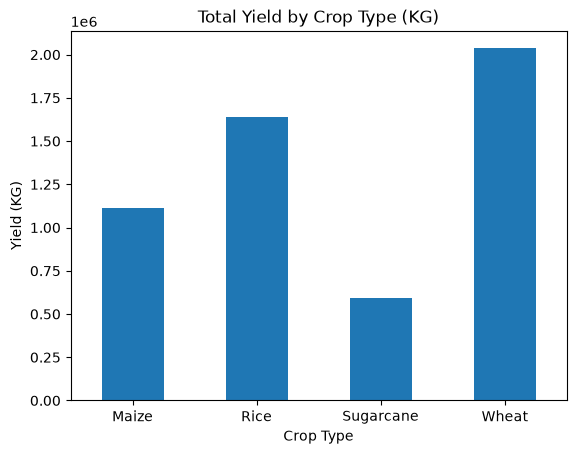

In [35]:
crop_yield.plot(kind='bar',title='Total Yield by Crop Type (KG)', legend=False)

plt.xlabel('Crop Type')
plt.ylabel('Yield (KG)')
plt.xticks(rotation=0)
plt.show()

In [36]:
pivot_df = df.pivot_table(values='YIELD_KG',index='HARVEST_DATE',aggfunc='sum')
pivot_df

,YIELD_KG
HARVEST_DATE,
2023-01-01,1500.0
2023-01-02,1500.0
2023-01-03,2500.0
2023-01-04,1500.0
2023-01-05,1500.0
...,...
2031-03-15,1500.0
2031-03-16,2000.0
2031-03-17,2000.0


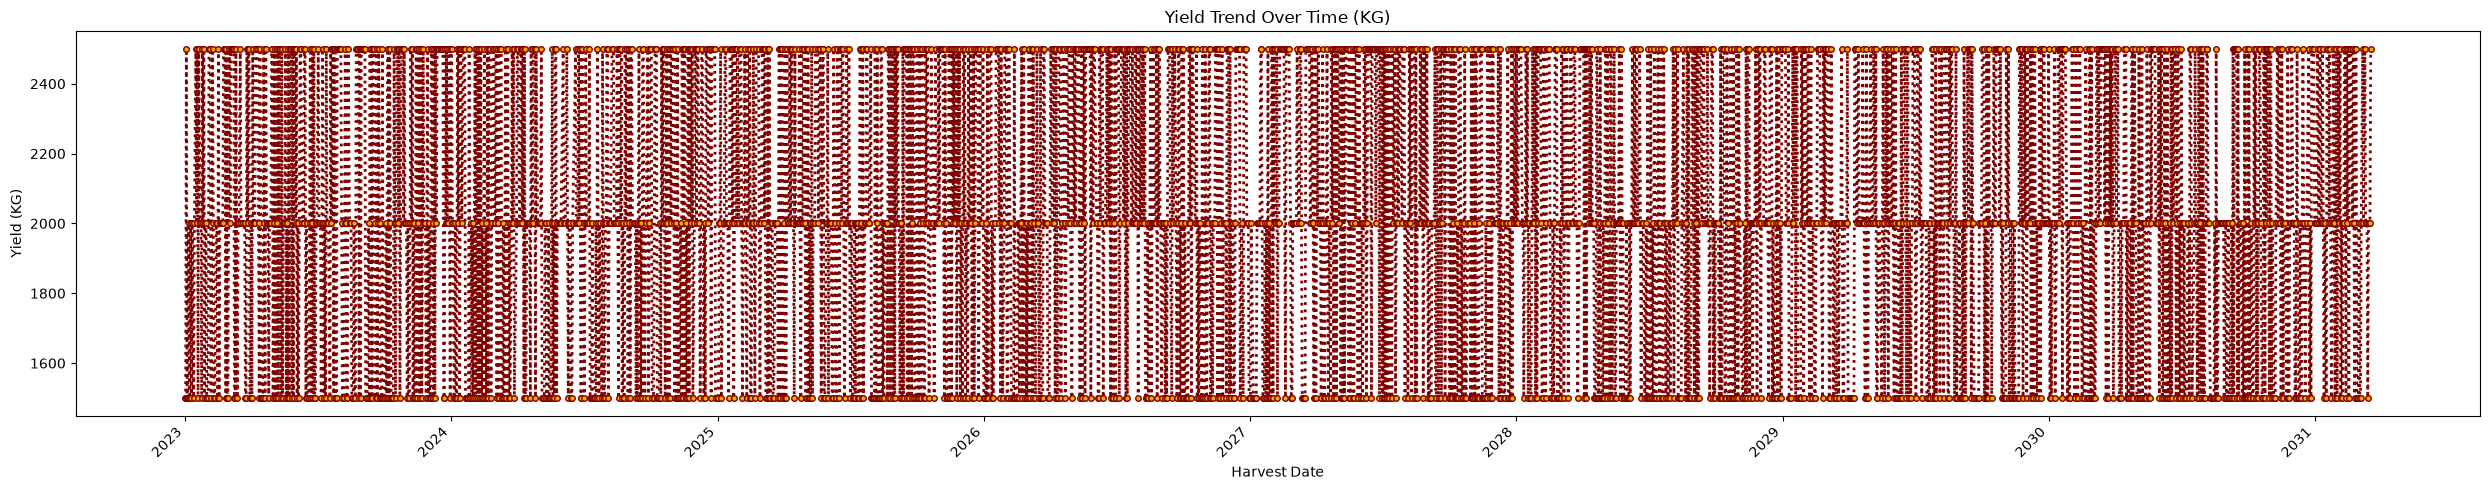

In [44]:
x = pivot_df.index
y = pivot_df['YIELD_KG'].values

plt.figure(figsize=(25, 5))
plt.xticks(rotation=45, ha="right")

plt.plot(x, y,marker="o",color="Maroon",linestyle=":",linewidth=2,markersize=4,mfc="orange")

plt.title("Yield Trend Over Time (KG)")
plt.xlabel("Harvest Date")
plt.ylabel("Yield (KG)")

plt.tight_layout()
plt.savefig('crop_yield_trend.png')
plt.show()